# 11. Two zeros

Run the cells from top to bottom. Select the `mano` kernel. The working directory may be `MANO` or `MANO/tutorial`.

All-zeros has two versions. Using the wrong one makes the model look broken: the fingers bend by themselves, or you cannot straighten them.

## Axis-angle zeros

`flat_hand=True` and `hand_pose` all zeros.

The 45 finger axis-angles are 0. Every finger rotation is the identity, and the pose blend is 0. The result is the flat template from registration.

Use this version when a joint angle has to be exact, and give `hand_pose` length 45.

## PCA-coefficient zeros

The official file compresses the 45-D finger axis-angles onto principal components:

```text
finger axis-angle = hands_mean + coefficients @ hands_components[:n]
```

`hands_components` is `(45, 45)`. If you use the first `n` rows, the coefficient vector has length `n`. The switch in `forward` is `pose_is_pca=True`.

`flat_hand=False` with 45 axis-angles set directly to 0 does the same thing as PCA coefficients of 0: the code adds `hands_mean` back.

The next cell draws both hands. The wrist coordinates should match, because `hands_mean` contains no global rotation.


norm of hands_mean 2.3246
first 6 entries of hands_mean [ 0.1117 -0.0429  0.4164  0.1088  0.066   0.7562]
mean rz of the index MCP, degrees 23.9
wrist difference, metres [0. 0. 0.]
gap over all 16 joints, cm 9.88
change in index-tip Y, mm -58.7
vertex gap between 6 PCA zeros and flat_hand=False 0.0


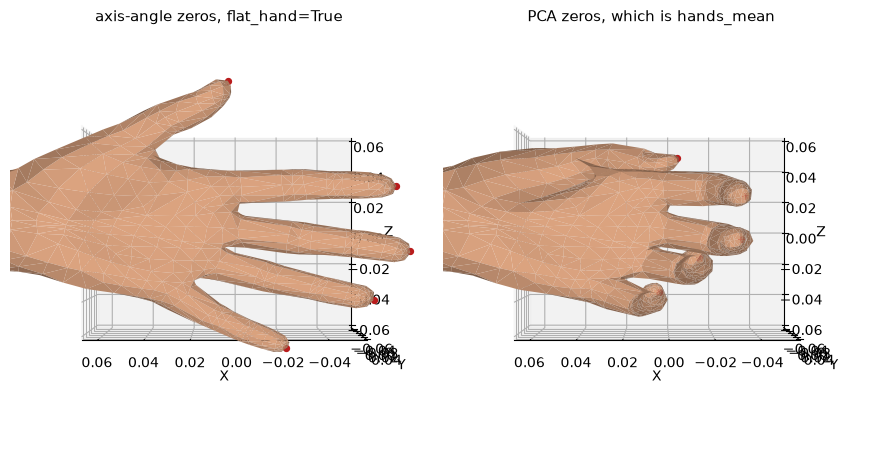

In [ ]:
import sys
from pathlib import Path

import numpy as np

MANO = Path.cwd().resolve()
if not (MANO / "mano_skeleton.py").exists():
    MANO = MANO.parent
if str(MANO) not in sys.path:
    sys.path.insert(0, str(MANO))

%matplotlib inline
from official_mano import require_model

model = require_model()
def show_hands(panels, faces, titles):
    """View the mesh from the palm side (-Y). Red points are the five fingertips."""
    import matplotlib.pyplot as plt
    from mpl_toolkits.mplot3d.art3d import Poly3DCollection

    palm = np.array([0.0, -1.0, 0.0])
    cloud = np.vstack([item["vertices"] for item in panels])
    fig = plt.figure(figsize=(4.4 * len(panels), 4.6))
    for index, (title, result) in enumerate(zip(titles, panels), start=1):
        axis = fig.add_subplot(1, len(panels), index, projection="3d")
        triangles = result["vertices"][faces]
        normals = np.cross(triangles[:, 1] - triangles[:, 0], triangles[:, 2] - triangles[:, 0])
        normals /= np.maximum(np.linalg.norm(normals, axis=1, keepdims=True), 1e-12)
        facing = normals @ palm > 0.0
        shade = 0.55 + 0.45 * np.abs(normals[facing] @ palm)
        color = np.zeros((int(facing.sum()), 4))
        color[:, 0] = 0.86 * shade
        color[:, 1] = 0.64 * shade
        color[:, 2] = 0.50 * shade
        color[:, 3] = 1.0
        axis.add_collection3d(Poly3DCollection(triangles[facing], facecolors=color, linewidths=0))
        tips = np.stack([result["tips"][name] for name in ("thumb", "index", "middle", "ring", "pinky")])
        axis.scatter(tips[:, 0], tips[:, 1], tips[:, 2], s=18, c="#b91c1c", depthshade=False)
        axis.set_title(title, fontsize=11)
        axis.view_init(elev=0, azim=90)
        axis.set_xlabel("X")
        axis.set_ylabel("Y")
        axis.set_zlabel("Z")
        center = cloud.mean(axis=0)
        radius = 0.55 * np.max(np.linalg.norm(cloud - center, axis=1))
        axis.set_xlim(center[0] - radius, center[0] + radius)
        axis.set_ylim(center[1] - radius, center[1] + radius)
        axis.set_zlim(center[2] - radius, center[2] + radius)
    fig.tight_layout()
    plt.show()

flat = model.forward(flat_hand=True)
mean = model.forward(flat_hand=False)
pca_zero = model.forward(hand_pose=np.zeros(6), flat_hand=False, pose_is_pca=True)

print("norm of hands_mean", round(float(np.linalg.norm(model.hands_mean)), 4))
print("first 6 entries of hands_mean", np.round(model.hands_mean[:6], 4))
print("mean rz of the index MCP, degrees", round(float(np.rad2deg(model.hands_mean[2])), 1))
print("wrist difference, metres", np.round(mean["joints"][0] - flat["joints"][0], 6))
print("gap over all 16 joints, cm", round(float(np.linalg.norm(mean["joints"] - flat["joints"]) * 100), 2))
print("change in index-tip Y, mm", round(float((mean["tips"]["index"][1] - flat["tips"]["index"][1]) * 1000), 1))
print(
    "vertex gap between 6 PCA zeros and flat_hand=False",
    float(np.linalg.norm(pca_zero["vertices"] - mean["vertices"])),
)

show_hands(
    [flat, mean],
    model.faces,
    ["axis-angle zeros, flat_hand=True", "PCA zeros, which is hands_mean"],
)


The mean axis-angle of the index MCP already has an rz of about 24 degrees. Coefficient zeros are therefore the mean pose of the training set: the fingers gather, and the thumb swings in front of the palm. The 16 joints together differ by about 9.9 cm. The index tip's Y drops by about 59 mm.

## Which call to use

| The numbers you have | Call |
|---|---|
| 45 axis-angles, and 0 means flat | `flat_hand=True`, `pose_is_pca=False` |
| 45 axis-angles, and 0 means the mean pose | `flat_hand=False`, `pose_is_pca=False` |
| `n` PCA coefficients, and 0 means the mean pose | `flat_hand=False`, `pose_is_pca=True` |

Six PCA coefficients can only represent a smooth family of gestures. The next cell asks the first 6 components to reconstruct "index PIP rz equals 1, and everything else is 0".


In [ ]:
target = np.zeros(45)
target[5] = 1.0  # rz of the index PIP
basis6 = model.hands_components[:6]
coeff, *_ = np.linalg.lstsq(basis6.T, target, rcond=None)
recon = coeff @ basis6
print("that component, recovered from 6 principal components", round(float(recon[5]), 3))
print("length that leaked onto other joints", round(float(np.linalg.norm(recon - target)), 3))

basis45 = model.hands_components[:45]
coeff45, *_ = np.linalg.lstsq(basis45.T, target, rcond=None)
recon45 = coeff45 @ basis45
print("error with all 45 principal components", round(float(np.linalg.norm(recon45 - target)), 6))


that component, recovered from 6 principal components 0.527
length that leaked onto other joints 0.688
error with all 45 principal components 0.0


The first 6 components recover about 0.53 of that one angle, and the rest leaks onto other joints. All 45 components reconstruct it exactly. When the joint angle itself is the quantity you care about, use the 45-D axis-angles.

To reach the flat template in PCA space, the coefficients have to cancel `hands_mean`. They are not zeros. In axis-angle space the same request is: write zeros, and set `flat_hand=True`.

## Check

`betas` is 0, `hand_pose` is 0, and `flat_hand=False`. That is the mean pose in `hands_mean`. The fingers are bent. The flat template uses `flat_hand=True`.

The next chapter collects the calls into cells you can edit and run again.
